# Representação vetorial de textos

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/03_representacao_vetorial_de_textos.ipynb)

Os notebooks anteriores compararam quantidades entre grupos. Para comparar
documentos, precisamos primeiro decidir como um texto se torna uma estrutura
calculável.

## 1. *Bag of Words*: o que preserva e o que perde

*Bag of Words* representa um documento pelas frequências dos termos. Preserva
parte do vocabulário e da repetição, mas descarta ordem, sintaxe, ironia,
negação, voz e grande parte do contexto.

`"trabalho não é progresso"` e `"progresso não é trabalho"` recebem as mesmas
contagens sob esta representação. Isso não é erro de programação: é uma perda
deliberada do modelo. **No nosso projeto essa perda não é hipotética**: em 2023
Lula usa *"a liberdade que eles pregam é a de oprimir"* para **recusar** um
sentido; BoW e TF-IDF contam essa ocorrência de `liberdade` exatamente como
contam a de Sarney em 1985, *"a liberdade é um legado de Deus"* — afirmação. A
representação vetorial não distingue afirmar de negar um conceito.

![Documentos preservados passam por normalização e tokens, formam um vocabulário e chegam a uma matriz de documentos por termos; uma nota registra a perda de ordem e sintaxe.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/03_fluxo_matriz_documento_termo.svg?raw=1)

In [ ]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


In [ ]:
import math
import re
import unicodedata
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv("dados/derivados/documentos_processaveis.csv").sort_values("ano")

def remover_acentos(texto):
    normalizado = unicodedata.normalize("NFKD", texto)
    return "".join(ch for ch in normalizado if not unicodedata.combining(ch))

STOPWORDS_ACENTUADAS = {
    "a", "e", "o", "de", "do", "da", "dos", "das", "em", "no", "na", "nos", "nas",
    "um", "uma", "que", "com", "por", "para", "se", "ao", "aos", "à", "às", "não",
    "sua", "seu", "suas", "seus", "mais", "como", "mas", "ou", "nossa", "nosso",
    "nossas", "nossos", "esta", "este", "isso", "sem", "ser", "foi", "já",
    "também", "é", "os", "as", "ele", "ela", "eles", "elas", "lhe", "meu",
    "minha", "meus", "minhas",
}
stopwords = {remover_acentos(s) for s in STOPWORDS_ACENTUADAS}

def tokenizar(texto):
    normalizado = remover_acentos(texto.lower())
    return [t for t in re.findall(r"[a-z]+", normalizado) if t not in stopwords]

# unidade de análise: o discurso inteiro (dados/brutos/), não o trecho —
# comparar documentos exige o texto completo, não só as janelas em torno do termo-alvo
docs["texto"] = [open(f"dados/brutos/{a}", encoding="utf-8").read() for a in docs["arquivo_bruto"]]
docs["tokens"] = docs["texto"].map(tokenizar)
docs.set_index("id_doc")[["ano", "presidente"]].assign(
    n_tokens_pos_stopwords=docs["tokens"].map(len).values
)

,ano,presidente,n_tokens_pos_stopwords
id_doc,,,
DISCURSO_1985_SARNEY,1985,José Sarney,2319
DISCURSO_1990_COLLOR,1990,Fernando Collor de Mello,3508
DISCURSO_1992_ITAMAR,1992,Itamar Franco,349
DISCURSO_1995_FHC,1995,Fernando Henrique Cardoso,1892
DISCURSO_1999_FHC,1999,Fernando Henrique Cardoso,1544
DISCURSO_2003_LULA,2003,Luiz Inácio Lula da Silva,2249
DISCURSO_2007_LULA,2007,Luiz Inácio Lula da Silva,2277
DISCURSO_2011_DILMA,2011,Dilma Rousseff,2208
DISCURSO_2015_DILMA,2015,Dilma Rousseff,2620


A função explicita minúsculas, remoção de acentos, tokenização e *stopwords*, as mesmas 12 letras minúsculas + acento não fazem diferença aqui, pois o texto
já foi despojado de acentos antes da comparação com a lista. Outra regra
produziria outro vocabulário: incluir `liberdade` na lista de stopwords, por
exemplo, apagaria o próprio objeto da pesquisa. Preservamos `texto` e `id_doc`
para poder retornar à fonte.

## 2. Matriz documento-termo

Se $c(t,d)$ é a contagem do termo $t$ no documento $d$, a matriz é:

$$
X_{d,t}=c(t,d).
$$

Linhas representam documentos; colunas, termos; células, frequências. Zero
significa ausência segundo as regras adotadas, não irrelevância histórica.

In [ ]:
contagens = [Counter(tokens) for tokens in docs["tokens"]]
matriz_contagens = pd.DataFrame(contagens, index=docs["id_doc"]).fillna(0).astype(int)
matriz_contagens.index.name = "id_doc"
vocabulario = sorted(matriz_contagens.columns)
print("Dimensões:", matriz_contagens.shape)
print("Vocabulário:", len(vocabulario), "termos")
matriz_contagens[["liberdade", "governo", "pais", "vamos"]]

Dimensões: (12, 6240)
Vocabulário: 6240 termos


,liberdade,governo,pais,vamos
id_doc,,,,
DISCURSO_1985_SARNEY,18,23,17,5
DISCURSO_1990_COLLOR,7,25,12,0
DISCURSO_1992_ITAMAR,0,8,3,0
DISCURSO_1995_FHC,7,14,10,8
DISCURSO_1999_FHC,1,6,17,1
DISCURSO_2003_LULA,0,9,21,10
DISCURSO_2007_LULA,0,13,22,6
DISCURSO_2011_DILMA,3,19,22,6
DISCURSO_2015_DILMA,2,12,18,16


A matriz torna os documentos comparáveis, mas termos recorrentes em toda a
coleção podem dominar a contagem. TF-IDF acrescenta uma ponderação pela raridade
documental.

## 3. TF, DF, IDF e TF-IDF

Neste notebook, TF é a contagem bruta. A frequência de documento usa presença
positiva, e a convenção de IDF é suavizada:

$$
df(t)=\sum_{d=1}^{N}\mathbf{1}(X_{d,t}>0),\qquad
idf(t)=\log\left(\frac{N+1}{df(t)+1}\right)+1.
$$

Finalmente:

$$
tfidf(t,d)=X_{d,t}\times idf(t).
$$

A suavização, a base do logaritmo e a normalização variam entre implementações;
documentá-las é parte do método.

![TF mede frequência no documento, IDF mede raridade entre documentos e seu produto gera um peso; a figura alerta que peso não é importância histórica.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/03_anatomia_tfidf.svg?raw=1)

In [ ]:
N = len(matriz_contagens)
frequencia_documento = matriz_contagens.gt(0).sum(axis=0)
idf = ((N + 1) / (frequencia_documento + 1)).map(math.log) + 1
matriz_tfidf = matriz_contagens.mul(idf, axis=1)

# Usando DISCURSO_1985_SARNEY
documento_exemplo = "DISCURSO_1985_SARNEY"
comparacao_pesos = pd.DataFrame({
    "contagem": matriz_contagens.loc[documento_exemplo],
    "df": frequencia_documento,
    "idf": idf,
    "tfidf": matriz_tfidf.loc[documento_exemplo],
}).sort_values("tfidf", ascending=False)
comparacao_pesos.head(10).round(3)

,contagem,df,idf,tfidf
governo,23,12,1.000,23.000
liberdade,18,9,1.262,22.723
setor,14,9,1.262,17.673
pais,17,12,1.000,17.000
tem,14,11,1.080,15.121
trilhoes,5,1,2.872,14.359
social,12,10,1.167,14.005
todos,14,12,1.000,14.000
divida,9,7,1.486,13.370
juros,6,3,2.179,13.072


Um peso alto identifica termo frequente no documento e relativamente raro na
coleção, sob esta regra. Não prova que o termo seja tema central, conceito
histórico ou escolha consciente do autor. `trilhões`, por exemplo, tem peso alto em Sarney 1985 só porque nenhum outro discurso do corpus
usa cruzeiros como moeda, é um artefato da inflação de 1985, não um indício
de projeto de governo.

## 4. Comparar dois discursos do próprio corpus

Antes de comparar períodos, olhamos o vocabulário de maior peso em dois
discursos concretos: o de maior taxa de "liberdade" no início da série
(Sarney, 1985) e o mais recente (Lula, 2023).

## 4. Comparar períodos e coleções

Agregar vetores por período permite localizar termos distintivos, mas o
agrupamento precisa ser definido antes da inspeção. Usamos o mesmo agrupamento
dos Notebooks 01 e 02 desta unidade, **Pontas** (1985, 1990, 1995, 2019, 2023)
e **Centro** (1992, 1999, 2003, 2007, 2011, 2015, 2016), derivado de H2, e não
o corte cronológico simples da Figura 4 da Unidade 4. É um agrupamento
diferente: ali o corte era só "primeira metade × segunda metade" da série; aqui
isolamos as bordas do formato em U observado na taxa de "liberdade".

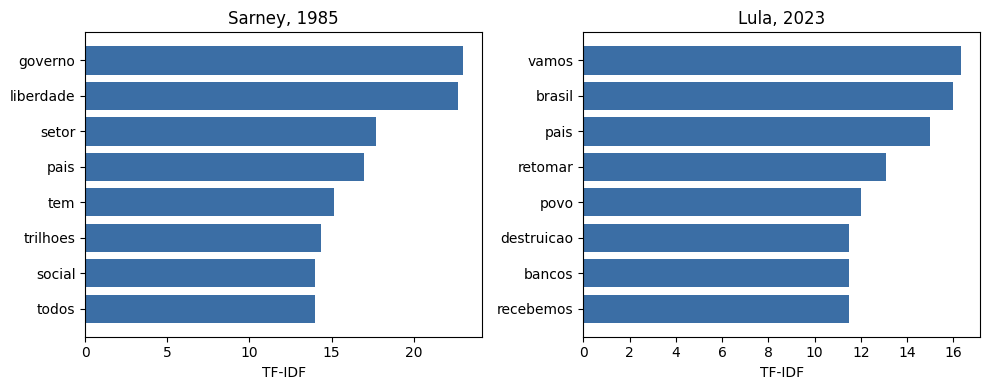

,contagem,df,idf,tfidf
vamos,14,10,1.167,16.339
brasil,16,12,1.000,16.000
pais,15,12,1.000,15.000
retomar,6,3,2.179,13.072
povo,12,12,1.000,12.000
destruicao,4,1,2.872,11.487
bancos,4,1,2.872,11.487
recebemos,4,1,2.872,11.487
ministerio,7,6,1.619,11.333
pela,11,12,1.000,11.000


In [ ]:
# Comparando DISCURSO_2023_LULA com DISCURSO_1985_SARNEY

documento_exemplo_2 = "DISCURSO_2023_LULA"
comparacao_pesos_2 = pd.DataFrame({
    "contagem": matriz_contagens.loc[documento_exemplo_2],
    "df": frequencia_documento,
    "idf": idf,
    "tfidf": matriz_tfidf.loc[documento_exemplo_2],
}).sort_values("tfidf", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for eixo, tabela, titulo in [(ax1, comparacao_pesos.head(8), "Sarney, 1985"),
                              (ax2, comparacao_pesos_2.head(8), "Lula, 2023")]:
    d = tabela.iloc[::-1]
    eixo.barh(d.index, d["tfidf"], color="#3b6ea5")
    eixo.set_title(titulo); eixo.set_xlabel("TF-IDF")
plt.tight_layout(); plt.show()

comparacao_pesos_2.head(10).round(3)

In [ ]:
PONTAS = {1985, 1990, 1995, 2019, 2023}
grupo = docs.set_index("id_doc")["ano"].map(lambda a: "Pontas" if a in PONTAS else "Centro")
media_tfidf_grupo = matriz_tfidf.groupby(grupo, observed=True).mean()
contraste_grupos = media_tfidf_grupo.loc["Pontas"] - media_tfidf_grupo.loc["Centro"]
termos_pontas = contraste_grupos.nlargest(8).rename("favorece Pontas")
termos_centro = contraste_grupos.nsmallest(8).rename("favorece Centro")
tabela_contrastes = pd.concat([
    termos_pontas.rename("contraste").rename_axis("termo").reset_index().assign(sentido="maior em Pontas"),
    termos_centro.rename("contraste").rename_axis("termo").reset_index().assign(sentido="maior em Centro"),
], ignore_index=True)
tabela_contrastes[["termo", "contraste", "sentido"]].round(3)

,termo,contraste,sentido
0,liberdade,9.089,maior em Pontas
1,brasil,5.171,maior em Pontas
2,nem,4.881,maior em Pontas
3,cidadania,4.661,maior em Pontas
4,papel,4.414,maior em Pontas
5,inflacao,4.400,maior em Pontas
6,divida,4.287,maior em Pontas
7,governo,4.029,maior em Pontas
8,eu,-7.394,maior em Centro
9,pais,-5.829,maior em Centro


O contraste depende do conteúdo repetitivo criado para os dados fictícios e da
distribuição dos temas pelos anos. Para interpretar um termo, retorne aos textos
e concordâncias; o peso não explica por que ele aparece.

## U05-A04 — Atividade integrada — matriz documentada

**Modalidade:** dupla. **Tempo:** 35 minutos.

1. documente tokenização e vocabulário;
2. construa uma matriz documento-termo;
3. compare contagem e TF-IDF em dois documentos;
4. identifique dois termos distintivos entre subconjuntos;
5. leia os trechos e registre uma interpretação e uma perda do modelo.

**Minha regra e matriz**

- **Tokenização:** minúsculas, acentos removidos (`unicodedata.normalize("NFKD", ...)`),
  `re.findall(r"[a-z]+")`, remoção de uma lista curta de 26 stopwords (artigos,
  preposições, pronomes), sem *stemming* nem lematização.
- **Unidade:** o discurso inteiro (`dados/brutos/`), não o trecho de 3 sentenças
  usado nas Unidades 3–4 pois comparar documentos exige o texto completo.
- **Matriz:** 12 documentos × 6.240 termos, contagem bruta; TF-IDF com
  `idf = log((N+1)/(df+1)) + 1`, a mesma convenção suavizada do notebook.

**Termos e trechos examinados**

Agrupamento Pontas (1985, 1990, 1995, 2019, 2023) × Centro (1992, 1999, 2003,
2007, 2011, 2015, 2016), o mesmo de H2 nos Notebooks 01 e 02 desta unidade.

- **`liberdade`** (favorece Pontas, contraste +9,089, o maior de toda a tabela):
  confirma H2 pelo lado lexical, não só pela taxa numérica já vista. Em Sarney
  1985, *"a liberdade é um legado de Deus"*; em Lula 2023, o mesmo termo aparece
  para recusar um sentido *"a liberdade que eles pregam é a de oprimir"*.
  O peso TF-IDF agregado do grupo não separa essas duas funções.
- **`país`** (favorece Centro, contraste −5,829): presente em todos os 12
  discursos (`df = 12`, IDF mínimo); o contraste vem de frequência relativa mais
  alta no grupo Centro, não de raridade.

**Perdas da representação**

A perda mais concreta do nosso corpus: BoW e TF-IDF tratam toda ocorrência de
`liberdade` como equivalente, então não distinguem afirmar de negar o
conceito. Em 2023, `liberdade` recebe peso alto no vocabulário de Lula, mas
metade das ocorrências ali é polêmica *"a liberdade que eles pregam é a de
oprimir o vulnerável"*, enquanto em 1985 o mesmo peso alto vem de afirmação
direta do conceito. A matriz não sabe a diferença; só o retorno ao trecho (como
foi feito nas Unidades 3 e 4) revela isso. `trilhões`, por sua vez, mostra outra
perda: um termo de peso alto por ser raro no corpus pode ser artefato de
conjuntura (a moeda de 1985), não indício de tema relevante.

Leve a matriz e suas regras ao Notebook 04. A partir delas calcularemos Jaccard
e cosseno e as compararemos à distância de edição entre versões — inclusive
entre os dois discursos de Lula mais distantes no tempo (2003 e 2023), para ver
se a semelhança vetorial capta ou não a disputa de sentido identificada acima.